### Librerias

In [ ]:
import pandas as pd
import numpy as np
import warnings
import time
import matplotlib.pyplot as plt

from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

from sklearn.metrics import mean_squared_error, mean_absolute_error

warnings.filterwarnings("ignore")
plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["axes.grid"] = True

print("Librerías cargadas correctamente.")

Librerías cargadas correctamente.


### Carga de datos

In [ ]:
ruta_archivo = "datosUVR.xlsx"

df = pd.read_excel(
    ruta_archivo,
    sheet_name="Series de datos",
    header=None,
    skiprows=4,
    usecols="A:B"
)

df.columns = ["date", "UVR"]
df["date"] = pd.to_datetime(df["date"], errors="coerce")
df["UVR"] = pd.to_numeric(df["UVR"], errors="coerce")

df = df.dropna(subset=["date", "UVR"])
fecha_limite = pd.Timestamp("2026-10-31")
df = df[df["date"] <= fecha_limite]
df = df.sort_values("date")
df = (
    df.set_index("date")
      .resample("ME")
      .last()
      .dropna(subset=["UVR"])
      .reset_index()
)

ruta_csv = "UVR_mensual.csv"
df.to_csv(ruta_csv, index=False, date_format="%Y-%m-%d")

print("Datos cargados y procesados correctamente.")
print(f"Dimensiones: {df.shape}")
print(f"Archivo guardado: {ruta_csv}")

print("\nPrimeros registros:")
print(df.head())

print("\nÚltimos registros:")
print(df.tail())

print("\nPeriodo:")
print(f"Desde: {df['date'].min().date()}")
print(f"Hasta: {df['date'].max().date()}")

Datos cargados y procesados correctamente.
Dimensiones: (406, 2)
Archivo guardado: UVR_mensual.csv

Primeros registros:
        date      UVR
0 1993-01-31  31.6330
1 1993-02-28  32.2505
2 1993-03-31  33.3538
3 1993-04-30  34.1925
4 1993-05-31  34.8564

Últimos registros:
          date       UVR
401 2026-06-30  414.7340
402 2026-07-31  416.5435
403 2026-08-31  417.6948
404 2026-09-30  418.8527
405 2026-10-31  420.4693

Periodo:
Desde: 1993-01-31
Hasta: 2026-10-31


In [ ]:
faltantes = df.isna().sum()

print("Valores faltantes:")
display(faltantes.to_frame("Valores faltantes"))

print("\nTotal de valores faltantes:", faltantes.sum())

Valores faltantes:


,Valores faltantes
date,0
UVR,0



Total de valores faltantes: 0


### Estadistico descriptivo

In [ ]:
estadisticas = df.describe().T

estadisticas

,count,mean,min,25%,50%,75%,max,std
date,406,2009-12-14 22:59:42.266009856,1993-01-31 00:00:00,2001-07-07 18:00:00,2009-12-15 12:00:00,2018-05-23 06:00:00,2026-10-31 00:00:00,NaN
UVR,406.0,191.886699,31.633,119.9835,186.7972,257.96315,420.4693,97.780088


### Serie de tiempo

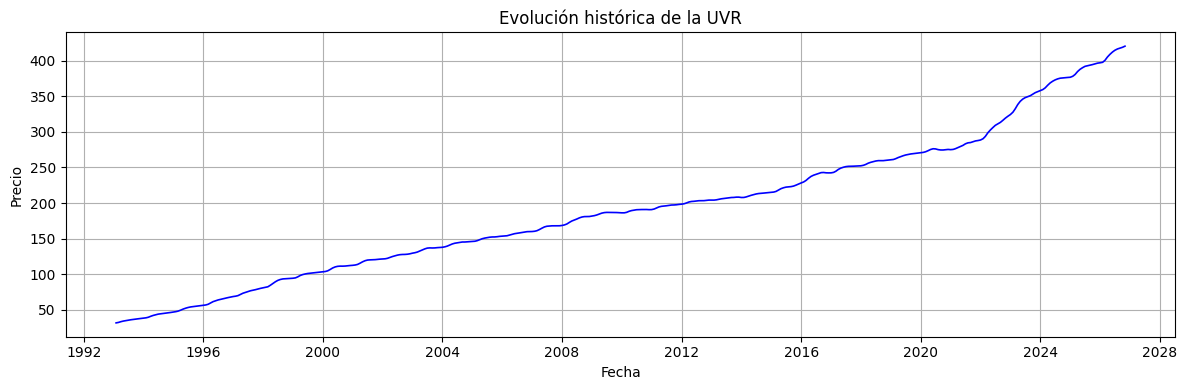

In [ ]:
plt.figure(figsize=(12, 4))
plt.plot(df["date"], df["UVR"], color="blue",
    linewidth=1.2)

plt.title(f"Evolución histórica de la UVR")
plt.xlabel("Fecha")
plt.ylabel("Precio")
plt.tight_layout()
plt.show()

### División de datos

In [ ]:

df = df.set_index("date").sort_index()
fecha_corte = "2024-10-31"
fecha_inicio_train = "2016-01-31"

train = df.loc[fecha_inicio_train:fecha_corte].copy()
test = df.loc["2024-11-01":].copy()


print("ENTRENAMIENTO")
print(
    train.index.min().date(),
    "-",
    train.index.max().date()
)

print("\nVALIDACIÓN")
print(
    test.index.min().date(),
    "-",
    test.index.max().date()
)

print("\nObservaciones entrenamiento:", len(train))
print("Observaciones validación:", len(test))

ENTRENAMIENTO
2016-01-31 - 2024-10-31

VALIDACIÓN
2024-11-30 - 2026-10-31

Observaciones entrenamiento: 106
Observaciones validación: 24


### Pueba ADF - Estacionariedad

In [ ]:
serie = train["UVR"].dropna()

resultado = adfuller(serie)

df_adf = pd.DataFrame([{
    "Variable": "UVR",
    "ADF Statistic": resultado[0],
    "p-value": resultado[1],
    "Estacionaria (5%)": resultado[1] < 0.05
}])

display(df_adf)

,Variable,ADF Statistic,p-value,Estacionaria (5%)
0,UVR,0.045643,0.962148,False


### Prueba de Jung-Box

In [ ]:
serie = train["UVR"].dropna()

resultado_lb = acorr_ljungbox(
    serie,
    lags=[5, 10, 15],
    return_df=True
)

display(resultado_lb)

,lb_stat,lb_pvalue
5,452.225418,1.626400e-95
10,768.174495,1.429127e-158
15,968.021461,9.596101e-197


### Escoger modelo ARIMA

In [ ]:
def obtener_d_optimo(serie, max_d=2, alpha=0.05):
    serie_actual = serie.dropna().copy()

    for d in range(max_d + 1):
        p_value = adfuller(serie_actual)[1]

        if p_value < alpha:
            return d

        serie_actual = serie_actual.diff().dropna()

    return max_d


# Calcular d óptimo para la UVR
d_optimo = obtener_d_optimo(train["UVR"])

# Mostrar resultados
df_d = pd.DataFrame([{
    "Variable": "UVR",
    "d óptimo": d_optimo
}])

display(df_d)

,Variable,d óptimo
0,UVR,2


In [ ]:
def optimizar_arima(
    serie,
    d,
    max_p=5,
    max_q=5,
    alpha=0.05
):
    mejor_aic = np.inf
    mejor_bic = np.inf
    mejor_orden = None
    mejor_modelo = None

    candidatos = []

    for p in range(max_p + 1):
        for q in range(max_q + 1):

            try:
                modelo = ARIMA(
                    serie,
                    order=(p, d, q)
                )

                resultado = modelo.fit()

                pvalues = resultado.pvalues
                parametros = pvalues
                significativos = (
                    len(parametros) > 0
                    and (parametros < alpha).all()
                )

                candidatos.append({
                    "p": p,
                    "d": d,
                    "q": q,
                    "AIC": resultado.aic,
                    "BIC": resultado.bic,
                    "Todos significativos": significativos,
                    "Máximo valor p": (
                        parametros.max()
                        if len(parametros) > 0
                        else np.nan
                    )
                })

                if significativos and resultado.aic < mejor_aic:
                    mejor_aic = resultado.aic
                    mejor_bic = resultado.bic
                    mejor_orden = (p, d, q)
                    mejor_modelo = resultado

            except Exception:
                continue

    tabla_candidatos = pd.DataFrame(candidatos)

    if not tabla_candidatos.empty:
        tabla_candidatos = (
            tabla_candidatos
            .sort_values("AIC")
            .reset_index(drop=True)
        )

    return (
        mejor_orden,
        mejor_aic,
        mejor_bic,
        mejor_modelo,
        tabla_candidatos
    )


modelos_arima = {}
tablas_candidatos = {}
resultados_modelos = []

inicio = time.perf_counter()

activo = "UVR"

print(f"Optimizando {activo}...")

serie = train[activo].dropna()

d = int(
    df_d.loc[
        df_d["Variable"] == activo,
        "d óptimo"
    ].iloc[0]
)

(
    mejor_orden,
    mejor_aic,
    mejor_bic,
    mejor_modelo,
    tabla_candidatos
) = optimizar_arima(
    serie,
    d=d,
    max_p=5,
    max_q=5,
    alpha=0.05
)

tablas_candidatos[activo] = tabla_candidatos

if mejor_orden is not None:

    modelos_arima[activo] = mejor_modelo

    resultados_modelos.append({
        "Variable": activo,
        "p": mejor_orden[0],
        "d": mejor_orden[1],
        "q": mejor_orden[2],
        "Orden": mejor_orden,
        "AIC": mejor_aic,
        "BIC": mejor_bic
    })

    print(f"\nMejor modelo: ARIMA{mejor_orden}")
    print(f"AIC: {mejor_aic:.4f}")
    print(f"BIC: {mejor_bic:.4f}")

    print("\nValores p de los parámetros:")
    display(
        pd.DataFrame({
            "Parámetro": mejor_modelo.pvalues.index,
            "Valor p": mejor_modelo.pvalues.values
        })
    )

else:
    print(
        "\nNo se encontró ningún modelo en la búsqueda "
        "en el que todos los parámetros evaluados "
        "sean significativos al 5 %."
    )

tiempo_modelos = time.perf_counter() - inicio

print(
    f"\nOptimización terminada en "
    f"{tiempo_modelos / 60:.2f} minutos."
)


df_resultados_arima = pd.DataFrame(resultados_modelos)

print("\nModelo seleccionado:")
display(df_resultados_arima)

print("\nCandidatos con todos los parámetros significativos:")

if not tabla_candidatos.empty:
    display(
        tabla_candidatos[
            tabla_candidatos["Todos significativos"]
        ].sort_values("AIC").reset_index(drop=True)
    )

Optimizando UVR...

Mejor modelo: ARIMA(1, 2, 2)
AIC: 179.8540
BIC: 190.4316

Valores p de los parámetros:


,Parámetro,Valor p
0,ar.L1,2.710934e-14
1,ma.L1,2.031374e-03
2,ma.L2,2.021996e-12
3,sigma2,7.294076e-15



Optimización terminada en 0.27 minutos.

Modelo seleccionado:


,Variable,p,d,q,Orden,AIC,BIC
0,UVR,1,2,2,"(1, 2, 2)",179.854038,190.431602



Candidatos con todos los parámetros significativos:


,p,d,q,AIC,BIC,Todos significativos,Máximo valor p
0,1,2,2,179.854038,190.431602,True,2.031374e-03
1,0,2,4,180.269645,193.491600,True,2.216707e-03
2,2,2,1,180.516918,191.094482,True,7.394369e-12
3,2,2,0,186.043866,193.977038,True,1.767177e-04
4,0,2,3,186.984865,197.562428,True,8.291113e-03
5,0,2,1,187.148377,192.437159,True,2.493781e-11
6,1,2,0,198.011458,203.300240,True,2.193651e-07
7,0,2,0,210.515704,213.160095,True,4.197362e-12


In [ ]:
nivel_significancia = 0.05
residuos_uvr = modelos_arima["UVR"].resid.dropna()
prueba = acorr_ljungbox(
    residuos_uvr,
    lags=[10, 20],
    return_df=True
)

pval_10 = prueba.loc[10, "lb_pvalue"]
pval_20 = prueba.loc[20, "lb_pvalue"]
hay_correlacion = (
    "Sí"
    if (pval_10 < nivel_significancia)
    or (pval_20 < nivel_significancia)
    else "No"
)

df_ljungbox = pd.DataFrame([{
    "Variable": "UVR",
    "p-value lag 10": round(pval_10, 4),
    "p-value lag 20": round(pval_20, 4),
    "Autocorrelación residual": hay_correlacion
}])

display(df_ljungbox)

,Variable,p-value lag 10,p-value lag 20,Autocorrelación residual
0,UVR,0.0723,0.6466,No


### Validación y predicción

In [ ]:
activo = "UVR"
horizonte_total = 120  # 10 años

serie_train = train[activo].dropna().copy()
serie_test = test[activo].dropna().copy()

modelo_info = df_resultados_arima.loc[
    df_resultados_arima["Variable"] == activo
].iloc[0]

orden = (
    int(modelo_info["p"]),
    int(modelo_info["d"]),
    int(modelo_info["q"])
)

print(f"Modelo seleccionado: ARIMA{orden}")
print(f"Observaciones de entrenamiento: {len(serie_train)}")
print(f"Observaciones de validación: {len(serie_test)}")

modelo = ARIMA(
    serie_train,
    order=orden
)

resultado_arima = modelo.fit()

forecast = resultado_arima.get_forecast(
    steps=horizonte_total
)

predicciones = np.asarray(forecast.predicted_mean)
intervalos = forecast.conf_int(alpha=0.05)

fechas_futuras = pd.date_range(
    start=serie_train.index.max() + pd.offsets.MonthEnd(1),
    periods=horizonte_total,
    freq="ME"
)

pronostico_10_anios = pd.DataFrame(
    {
        "Pronóstico": predicciones,
        "Límite inferior": intervalos.iloc[:, 0].to_numpy(),
        "Límite superior": intervalos.iloc[:, 1].to_numpy()
    },
    index=pd.DatetimeIndex(fechas_futuras, name="date")
)

pronostico_10_anios["Valor real"] = serie_test.reindex(
    pronostico_10_anios.index
)

display(pronostico_10_anios)

Modelo seleccionado: ARIMA(1, 2, 2)
Observaciones de entrenamiento: 106
Observaciones de validación: 24


,Pronóstico,Límite inferior,Límite superior,Valor real
date,,,,
2024-11-30,377.193170,376.115812,378.270528,376.4971
2024-12-31,378.361641,375.574313,381.148969,376.7763
2025-01-31,379.724889,375.098986,384.350792,378.1629
2025-02-28,381.223289,374.731393,387.715185,380.6535
2025-03-31,382.815470,374.473648,391.157292,384.8110
...,...,...,...,...
2034-06-30,582.662370,335.533893,829.790846,NaN
2034-07-31,584.467134,334.549126,834.385141,NaN
2034-08-31,586.271897,333.554115,838.989680,NaN


In [ ]:
datos_validacion = pronostico_10_anios.dropna(
    subset=["Valor real"]
)

real = datos_validacion["Valor real"]
pred = datos_validacion["Pronóstico"]

rmse = np.sqrt(mean_squared_error(real, pred))
mae = mean_absolute_error(real, pred)
mape = np.mean(np.abs((real - pred) / real)) * 100

df_metricas_estatico = pd.DataFrame([
    {
        "Modelo": f"ARIMA{orden}",
        "RMSE": rmse,
        "MAE": mae,
        "MAPE (%)": mape,
        "Meses evaluados": len(datos_validacion),
        "Horizonte pronosticado": horizonte_total
    }
])

display(df_metricas_estatico.round(4))

,Modelo,RMSE,MAE,MAPE (%),Meses evaluados,Horizonte pronosticado
0,"ARIMA(1, 2, 2)",3.0898,2.667,0.6625,24,120


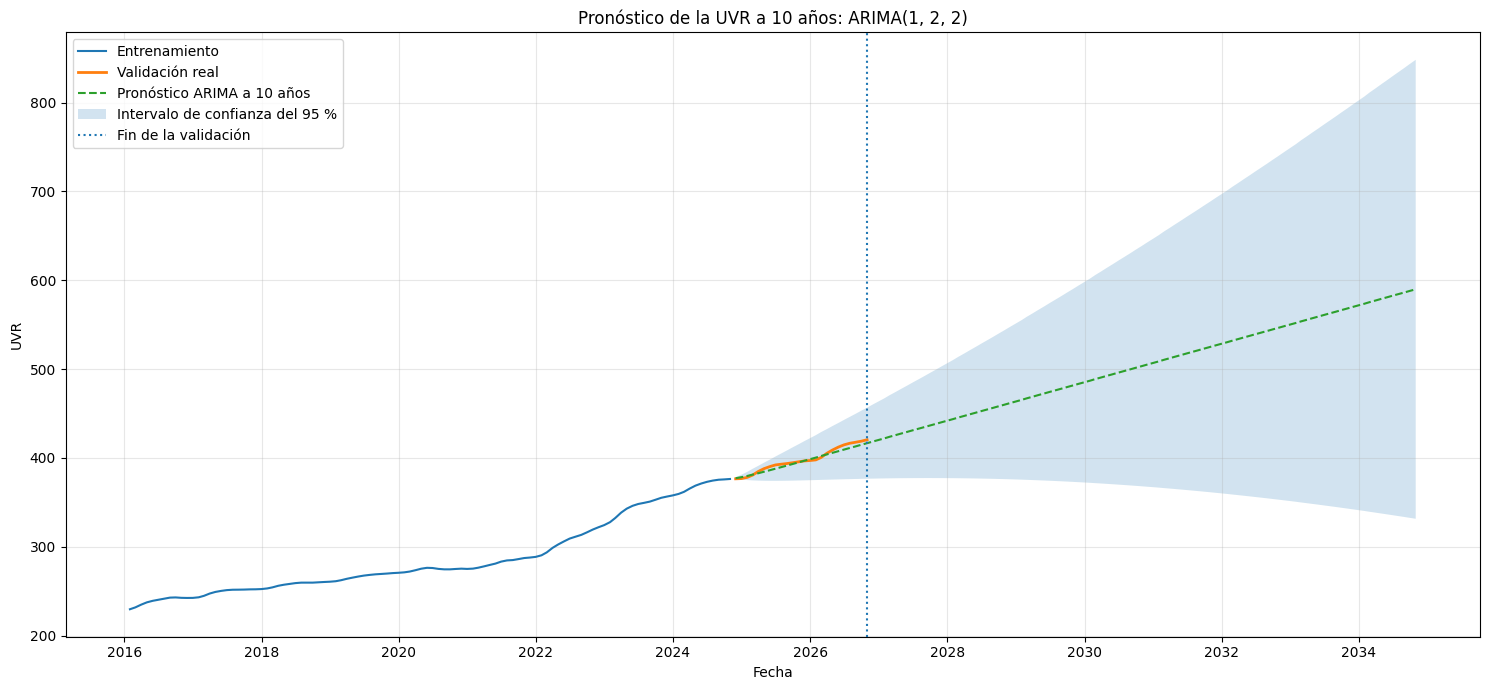

In [ ]:
plt.figure(figsize=(15, 7))

plt.plot(
    serie_train.index,
    serie_train,
    label="Entrenamiento",
    linewidth=1.5
)

plt.plot(
    serie_test.index,
    serie_test,
    label="Validación real",
    linewidth=2
)

plt.plot(
    pronostico_10_anios.index,
    pronostico_10_anios["Pronóstico"],
    linestyle="--",
    label="Pronóstico ARIMA a 10 años"
)

plt.fill_between(
    pronostico_10_anios.index,
    pronostico_10_anios["Límite inferior"],
    pronostico_10_anios["Límite superior"],
    alpha=0.2,
    label="Intervalo de confianza del 95 %"
)

plt.axvline(
    serie_test.index.max(),
    linestyle=":",
    label="Fin de la validación"
)

plt.title(f"Pronóstico de la UVR a 10 años: ARIMA{orden}")
plt.xlabel("Fecha")
plt.ylabel("UVR")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
import pandas as pd
from IPython.display import display

# ============================================================
# 1. PARÁMETROS DEL CRÉDITO
# ============================================================

capital_inicial_uvr = 1_000_000
plazo_meses = 120
tasa_ea = 0.10
cuota_uvr = 20_379.53
meses_gracia = 36

# Abonos extraordinarios: mes -> valor en UVR
abonos_programados = {
    48: 50_000,  # Final del año 4
    60: 50_000   # Final del año 5
}

# Tasa efectiva mensual equivalente al 10% EA
tasa_mensual = (1 + tasa_ea)**(1/12) - 1


# ============================================================
# 2. EXTRAER LAS PREDICCIONES DE UVR
# ============================================================

# Usamos las predicciones del DataFrame que ya generaste
pronostico_uvr = pronostico_10_anios["Pronóstico"].copy()

# Verificaciones
if len(pronostico_uvr) != plazo_meses:
    raise ValueError(
        f"Se esperaban {plazo_meses} predicciones, "
        f"pero se encontraron {len(pronostico_uvr)}."
    )

if pronostico_uvr.isna().any():
    raise ValueError("Hay valores faltantes en las predicciones de UVR.")

if not np.isfinite(pronostico_uvr.to_numpy()).all():
    raise ValueError("Las predicciones contienen valores no finitos.")

if (pronostico_uvr <= 0).any():
    raise ValueError("Los valores pronosticados de UVR deben ser positivos.")

print(f"Modelo ARIMA utilizado: ARIMA{orden}")
print(f"Primera fecha pronosticada: {pronostico_uvr.index.min().date()}")
print(f"Última fecha pronosticada: {pronostico_uvr.index.max().date()}")
print(f"Tasa efectiva mensual: {tasa_mensual:.6%}")


# ============================================================
# 3. CONSTRUIR LA TABLA DE AMORTIZACIÓN
# ============================================================

saldo_uvr = capital_inicial_uvr
registros = []

for mes in range(1, plazo_meses + 1):

    fecha = pronostico_uvr.index[mes - 1]
    valor_uvr_cop = float(pronostico_uvr.iloc[mes - 1])

    # Saldo al inicio del período
    saldo_inicial_uvr = saldo_uvr

    # Intereses del mes calculados sobre el saldo inicial
    intereses_uvr = saldo_inicial_uvr * tasa_mensual

    # Inicializar pagos y abonos
    cuota_uvr_mes = 0.0
    abono_capital_cuota_uvr = 0.0
    abono_extraordinario_uvr = 0.0

    # --------------------------------------------------------
    # MESES 1 A 36: PERÍODO DE GRACIA
    # --------------------------------------------------------
    if mes <= meses_gracia:

        # No se pagan cuotas.
        # Los intereses se capitalizan.
        saldo_uvr = saldo_inicial_uvr + intereses_uvr

    # --------------------------------------------------------
    # MESES 37 A 120: PAGO DE CUOTAS
    # --------------------------------------------------------
    else:

        # Saldo total incluyendo los intereses del período
        saldo_antes_pagos_uvr = saldo_inicial_uvr + intereses_uvr

        # Cuota fija en UVR, limitada al saldo pendiente
        cuota_uvr_mes = min(cuota_uvr, saldo_antes_pagos_uvr)

        # Parte de la cuota que amortiza el capital
        abono_capital_cuota_uvr = max(
            0.0,
            cuota_uvr_mes - intereses_uvr
        )

        # Saldo después de pagar la cuota ordinaria
        saldo_despues_cuota_uvr = max(
            0.0,
            saldo_antes_pagos_uvr - cuota_uvr_mes
        )

        # Abono extraordinario programado para el mes
        abono_programado = abonos_programados.get(mes, 0.0)

        # El abono no puede superar la deuda pendiente
        abono_extraordinario_uvr = min(
            abono_programado,
            saldo_despues_cuota_uvr
        )

        # Saldo final del período
        saldo_uvr = max(
            0.0,
            saldo_despues_cuota_uvr - abono_extraordinario_uvr
        )

    # --------------------------------------------------------
    # CONVERSIÓN DE UVR A PESOS COLOMBIANOS
    # --------------------------------------------------------

    cuota_cop = cuota_uvr_mes * valor_uvr_cop
    intereses_cop = intereses_uvr * valor_uvr_cop

    abono_capital_cuota_cop = (
        abono_capital_cuota_uvr * valor_uvr_cop
    )

    abono_extraordinario_cop = (
        abono_extraordinario_uvr * valor_uvr_cop
    )

    pago_total_uvr = cuota_uvr_mes + abono_extraordinario_uvr
    pago_total_cop = cuota_cop + abono_extraordinario_cop

    registros.append({
        "Fecha": fecha,
        "Mes": mes,
        "Año": (mes - 1) // 12 + 1,
        "Valor UVR (COP)": valor_uvr_cop,

        "Saldo inicial (UVR)": saldo_inicial_uvr,
        "Intereses (UVR)": intereses_uvr,
        "Cuota ordinaria (UVR)": cuota_uvr_mes,
        "Abono a capital por cuota (UVR)": abono_capital_cuota_uvr,
        "Abono extraordinario (UVR)": abono_extraordinario_uvr,
        "Pago total (UVR)": pago_total_uvr,
        "Saldo final (UVR)": saldo_uvr,

        "Saldo inicial (COP)": saldo_inicial_uvr * valor_uvr_cop,
        "Intereses (COP)": intereses_cop,
        "Cuota ordinaria (COP)": cuota_cop,
        "Abono a capital por cuota (COP)": abono_capital_cuota_cop,
        "Abono extraordinario (COP)": abono_extraordinario_cop,
        "Pago total (COP)": pago_total_cop,
        "Saldo final (COP)": saldo_uvr * valor_uvr_cop
    })


tabla_amortizacion = pd.DataFrame(registros)


# ============================================================
# 4. RESUMEN DEL CRÉDITO
# ============================================================

print("\n" + "=" * 70)
print("RESUMEN DEL CRÉDITO EN UVR")
print("=" * 70)

print(f"Capital inicial: {capital_inicial_uvr:,.2f} UVR")
print(f"Tasa efectiva anual: {tasa_ea:.2%}")
print(f"Tasa efectiva mensual: {tasa_mensual:.6%}")
print(f"Cuota mensual pactada: {cuota_uvr:,.2f} UVR")

# Promedio de las cuotas ordinarias durante los 120 meses.
# Incluye los 36 meses con cuota cero.
promedio_cuota_120_cop = tabla_amortizacion[
    "Cuota ordinaria (COP)"
].mean()

# Promedio de las cuotas ordinarias durante los meses 37 a 120.
cuotas_periodo_pago = tabla_amortizacion.loc[
    tabla_amortizacion["Mes"] > meses_gracia,
    "Cuota ordinaria (COP)"
]

promedio_cuota_84_cop = cuotas_periodo_pago.mean()

print("\n" + "=" * 70)
print("RESUMEN DE PAGOS EN PESOS COLOMBIANOS")
print("=" * 70)

print(
    f"Promedio mensual de cuota durante los 120 meses "
    f"(incluye los meses de gracia): "
    f"${promedio_cuota_120_cop:,.2f}"
)

print(
    f"Promedio mensual de cuota durante los 84 meses de pago: "
    f"${promedio_cuota_84_cop:,.2f}"
)

print(
    f"Total de cuotas ordinarias: "
    f"${tabla_amortizacion['Cuota ordinaria (COP)'].sum():,.2f}"
)

print(
    f"Total de abonos extraordinarios: "
    f"${tabla_amortizacion['Abono extraordinario (COP)'].sum():,.2f}"
)

print(
    f"Total de pagos del crédito: "
    f"${tabla_amortizacion['Pago total (COP)'].sum():,.2f}"
)

print(
    f"Saldo final después del mes 120: "
    f"{tabla_amortizacion['Saldo final (UVR)'].iloc[-1]:,.2f} UVR"
)


# ============================================================
# 5. TABLA DE ABONOS EXTRAORDINARIOS
# ============================================================

columnas_abonos = [
    "Fecha",
    "Mes",
    "Año",
    "Valor UVR (COP)",
    "Abono extraordinario (UVR)",
    "Abono extraordinario (COP)"
]

tabla_abonos = tabla_amortizacion.loc[
    tabla_amortizacion["Mes"].isin(abonos_programados.keys()),
    columnas_abonos
].copy()

print("\n" + "=" * 70)
print("ABONOS EXTRAORDINARIOS PROGRAMADOS")
print("=" * 70)

display(
    tabla_abonos.style.format({
        "Valor UVR (COP)": "${:,.4f}",
        "Abono extraordinario (UVR)": "{:,.2f}",
        "Abono extraordinario (COP)": "${:,.2f}"
    })
)


# ============================================================
# 6. TABLA DE AMORTIZACIÓN COMPLETA
# ============================================================

print("\n" + "=" * 70)
print("TABLA DE AMORTIZACIÓN COMPLETA")
print("=" * 70)

display(
    tabla_amortizacion.style.format({
        "Valor UVR (COP)": "${:,.4f}",
        "Saldo inicial (UVR)": "{:,.2f}",
        "Intereses (UVR)": "{:,.2f}",
        "Cuota ordinaria (UVR)": "{:,.2f}",
        "Abono a capital por cuota (UVR)": "{:,.2f}",
        "Abono extraordinario (UVR)": "{:,.2f}",
        "Pago total (UVR)": "{:,.2f}",
        "Saldo final (UVR)": "{:,.2f}",
        "Saldo inicial (COP)": "${:,.2f}",
        "Intereses (COP)": "${:,.2f}",
        "Cuota ordinaria (COP)": "${:,.2f}",
        "Abono a capital por cuota (COP)": "${:,.2f}",
        "Abono extraordinario (COP)": "${:,.2f}",
        "Pago total (COP)": "${:,.2f}",
        "Saldo final (COP)": "${:,.2f}"
    })
)


# ============================================================
# 7. EXPORTAR LOS RESULTADOS A EXCEL
# ============================================================

nombre_archivo = "amortizacion_credito_uvr.xlsx"

with pd.ExcelWriter(nombre_archivo, engine="openpyxl") as writer:

    tabla_amortizacion.to_excel(
        writer,
        sheet_name="Amortización",
        index=False
    )

    tabla_abonos.to_excel(
        writer,
        sheet_name="Abonos extraordinarios",
        index=False
    )

print(f"\nArchivo Excel generado: {nombre_archivo}")

Modelo ARIMA utilizado: ARIMA(1, 2, 2)
Primera fecha pronosticada: 2024-11-30
Última fecha pronosticada: 2034-10-31
Tasa efectiva mensual: 0.797414%

RESUMEN DEL CRÉDITO EN UVR
Capital inicial: 1,000,000.00 UVR
Tasa efectiva anual: 10.00%
Tasa efectiva mensual: 0.797414%
Cuota mensual pactada: 20,379.53 UVR

RESUMEN DE PAGOS EN PESOS COLOMBIANOS
Promedio mensual de cuota durante los 120 meses (incluye los meses de gracia): $7,346,588.43
Promedio mensual de cuota durante los 84 meses de pago: $10,495,126.33
Total de cuotas ordinarias: $881,590,612.09
Total de abonos extraordinarios: $47,076,701.52
Total de pagos del crédito: $928,667,313.61
Saldo final después del mes 120: 0.32 UVR

ABONOS EXTRAORDINARIOS PROGRAMADOS


,Fecha,Mes,Año,Valor UVR (COP),Abono extraordinario (UVR),Abono extraordinario (COP)
47,2028-10-31 00:00:00,48,4,$459.9384,"50,000.00","$22,996,921.62"
59,2029-10-31 00:00:00,60,5,$481.5956,"50,000.00","$24,079,779.89"



TABLA DE AMORTIZACIÓN COMPLETA


,Fecha,Mes,Año,Valor UVR (COP),Saldo inicial (UVR),Intereses (UVR),Cuota ordinaria (UVR),Abono a capital por cuota (UVR),Abono extraordinario (UVR),Pago total (UVR),Saldo final (UVR),Saldo inicial (COP),Intereses (COP),Cuota ordinaria (COP),Abono a capital por cuota (COP),Abono extraordinario (COP),Pago total (COP),Saldo final (COP)
0,2024-11-30 00:00:00,1,1,$377.1932,"1,000,000.00","7,974.14",0.00,0.00,0.00,0.00,"1,007,974.14","$377,193,169.93","$3,007,791.31",$0.00,$0.00,$0.00,$0.00,"$380,200,961.23"
1,2024-12-31 00:00:00,2,1,$378.3616,"1,007,974.14","8,037.73",0.00,0.00,0.00,0.00,"1,016,011.87","$381,378,750.25","$3,041,167.71",$0.00,$0.00,$0.00,$0.00,"$384,419,917.96"
2,2025-01-31 00:00:00,3,1,$379.7249,"1,016,011.87","8,101.82",0.00,0.00,0.00,0.00,"1,024,113.69","$385,804,993.38","$3,076,463.20",$0.00,$0.00,$0.00,$0.00,"$388,881,456.57"
3,2025-02-28 00:00:00,4,1,$381.2233,"1,024,113.69","8,166.43",0.00,0.00,0.00,0.00,"1,032,280.12","$390,415,988.69","$3,113,231.92",$0.00,$0.00,$0.00,$0.00,"$393,529,220.61"
4,2025-03-31 00:00:00,5,1,$382.8155,"1,032,280.12","8,231.55",0.00,0.00,0.00,0.00,"1,040,511.66","$395,172,797.72","$3,151,163.38",$0.00,$0.00,$0.00,$0.00,"$398,323,961.10"
5,2025-04-30 00:00:00,6,1,$384.4727,"1,040,511.66","8,297.19",0.00,0.00,0.00,0.00,"1,048,808.85","$400,048,354.32","$3,190,041.76",$0.00,$0.00,$0.00,$0.00,"$403,238,396.08"
6,2025-05-31 00:00:00,7,1,$386.1751,"1,048,808.85","8,363.35",0.00,0.00,0.00,0.00,"1,057,172.20","$405,023,897.75","$3,229,717.44",$0.00,$0.00,$0.00,$0.00,"$408,253,615.18"
7,2025-06-30 00:00:00,8,1,$387.9089,"1,057,172.20","8,430.04",0.00,0.00,0.00,0.00,"1,065,602.24","$410,086,477.88","$3,270,087.16",$0.00,$0.00,$0.00,$0.00,"$413,356,565.04"
8,2025-07-31 00:00:00,9,1,$389.6644,"1,065,602.24","8,497.26",0.00,0.00,0.00,0.00,"1,074,099.50","$415,227,210.34","$3,311,080.09",$0.00,$0.00,$0.00,$0.00,"$418,538,290.42"
9,2025-08-31 00:00:00,10,1,$391.4349,"1,074,099.50","8,565.02",0.00,0.00,0.00,0.00,"1,082,664.52","$420,440,056.10","$3,352,648.05",$0.00,$0.00,$0.00,$0.00,"$423,792,704.15"



Archivo Excel generado: amortizacion_credito_uvr.xlsx


In [ ]:
import numpy as np
import pandas as pd
from IPython.display import display

# ============================================================
# 1. PARÁMETROS DEL CRÉDITO
# ============================================================

capital_inicial_uvr = 1_000_000
plazo_meses = 120
tasa_ea = 0.10
cuota_uvr = 20_379.53
meses_gracia = 36

# Abonos extraordinarios: mes -> valor en UVR
abonos_programados = {
    48: 50_000,
    60: 50_000
}

# Tasa efectiva mensual
tasa_mensual = (1 + tasa_ea)**(1/12) - 1


# ============================================================
# 2. EXTRAER PREDICCIONES Y CALCULAR INFLACIÓN
# ============================================================

pronostico_uvr = pronostico_10_anios["Pronóstico"].copy()

if len(pronostico_uvr) != plazo_meses:
    raise ValueError(
        f"Se esperaban {plazo_meses} predicciones, "
        f"pero se encontraron {len(pronostico_uvr)}."
    )

if pronostico_uvr.isna().any():
    raise ValueError("Hay valores faltantes en las predicciones de UVR.")

if not np.isfinite(pronostico_uvr.to_numpy()).all():
    raise ValueError("Las predicciones contienen valores no finitos.")

if (pronostico_uvr <= 0).any():
    raise ValueError("Las predicciones de UVR deben ser positivas.")

# Último valor real de UVR anterior al horizonte de pronóstico
uvr_anterior = float(serie_train.dropna().iloc[-1])

# Construir secuencia: último valor observado + 120 predicciones
uvr_secuencia = np.concatenate([
    [uvr_anterior],
    pronostico_uvr.to_numpy(dtype=float)
])

# Inflación mensual: rendimiento entre valores consecutivos de UVR
inflacion_mensual = (
    uvr_secuencia[1:] / uvr_secuencia[:-1]
) - 1

# Tabla auxiliar de fechas, UVR e inflación
datos_uvr = pd.DataFrame({
    "Fecha": pronostico_uvr.index,
    "Inflación": inflacion_mensual,
    "UVR": pronostico_uvr.to_numpy(dtype=float)
})

print(f"Modelo ARIMA utilizado: ARIMA{orden}")
print(f"Primera fecha pronosticada: {pronostico_uvr.index.min().date()}")
print(f"Última fecha pronosticada: {pronostico_uvr.index.max().date()}")
print(f"Tasa efectiva anual del crédito: {tasa_ea:.2%}")
print(f"Tasa efectiva mensual del crédito: {tasa_mensual:.6%}")


# ============================================================
# 3. CONSTRUIR LA TABLA DE AMORTIZACIÓN
# ============================================================

saldo_uvr = capital_inicial_uvr
registros = []

for mes in range(1, plazo_meses + 1):

    fecha = pronostico_uvr.index[mes - 1]
    valor_uvr_cop = float(pronostico_uvr.iloc[mes - 1])
    inflacion = float(inflacion_mensual[mes - 1])

    # Saldo inicial del período, expresado en UVR
    saldo_inicial_uvr = saldo_uvr

    # Intereses del período, expresados en UVR
    intereses_uvr = saldo_inicial_uvr * tasa_mensual

    # Convertir saldo e intereses a COP usando la UVR del período
    saldo_inicial_cop = saldo_inicial_uvr * valor_uvr_cop
    intereses_cop = intereses_uvr * valor_uvr_cop

    # Componentes asociados a la inflación, en COP
    inflacion_cop = saldo_inicial_cop * inflacion
    intereses_inflacion_cop = intereses_cop * inflacion

    # Inicializar pagos
    cuota_uvr_mes = 0.0
    abono_capital_cuota_uvr = 0.0
    abono_extraordinario_uvr = 0.0

    # --------------------------------------------------------
    # MESES 1 A 36: PERÍODO DE GRACIA
    # --------------------------------------------------------
    if mes <= meses_gracia:

        # No se pagan cuotas; los intereses se capitalizan
        saldo_uvr = saldo_inicial_uvr + intereses_uvr

    # --------------------------------------------------------
    # MESES 37 A 120: AMORTIZACIÓN
    # --------------------------------------------------------
    else:

        saldo_antes_pagos_uvr = saldo_inicial_uvr + intereses_uvr

        # Cuota ordinaria fija en UVR
        cuota_uvr_mes = min(
            cuota_uvr,
            saldo_antes_pagos_uvr
        )

        # Abono a capital contenido en la cuota ordinaria
        abono_capital_cuota_uvr = max(
            0.0,
            cuota_uvr_mes - intereses_uvr
        )

        saldo_despues_cuota_uvr = max(
            0.0,
            saldo_antes_pagos_uvr - cuota_uvr_mes
        )

        # Abono extraordinario programado
        abono_programado = abonos_programados.get(mes, 0.0)

        # Evitar abonos superiores al saldo pendiente
        abono_extraordinario_uvr = min(
            abono_programado,
            saldo_despues_cuota_uvr
        )

        # Saldo final del período
        saldo_uvr = max(
            0.0,
            saldo_despues_cuota_uvr - abono_extraordinario_uvr
        )

    # --------------------------------------------------------
    # CONVERSIÓN DE LOS PAGOS Y SALDOS A COP
    # --------------------------------------------------------

    cuota_cop = cuota_uvr_mes * valor_uvr_cop

    abono_capital_cuota_cop = (
        abono_capital_cuota_uvr * valor_uvr_cop
    )

    abono_extraordinario_cop = (
        abono_extraordinario_uvr * valor_uvr_cop
    )

    pago_total_uvr = cuota_uvr_mes + abono_extraordinario_uvr
    pago_total_cop = cuota_cop + abono_extraordinario_cop

    saldo_final_cop = saldo_uvr * valor_uvr_cop

    # Registrar período
    registros.append({
        "Fecha": fecha,
        "Mes": mes,
        "Año": (mes - 1) // 12 + 1,

        # Inflación aparece antes de UVR
        "Inflación": inflacion,
        "UVR (COP)": valor_uvr_cop,

        "Saldo inicial (COP)": saldo_inicial_cop,
        "Intereses (COP)": intereses_cop,
        "Inflación (COP)": inflacion_cop,
        "Intereses inflación (COP)": intereses_inflacion_cop,

        "Intereses (UVR)": intereses_uvr,
        "Cuota (UVR)": cuota_uvr_mes,
        "Abono a capital por cuota (UVR)": abono_capital_cuota_uvr,
        "Abono extraordinario (UVR)": abono_extraordinario_uvr,
        "Pago total (UVR)": pago_total_uvr,
        "Saldo inicial (UVR)": saldo_inicial_uvr,
        "Saldo final (UVR)": saldo_uvr,

        "Cuota (COP)": cuota_cop,
        "Abono a capital por cuota (COP)": abono_capital_cuota_cop,
        "Abono extraordinario (COP)": abono_extraordinario_cop,
        "Pago total (COP)": pago_total_cop,
        "Saldo final (COP)": saldo_final_cop
    })


tabla_amortizacion = pd.DataFrame(registros)


# ============================================================
# 4. RESUMEN DEL CRÉDITO
# ============================================================

promedio_cuota_120_cop = tabla_amortizacion["Cuota (COP)"].mean()

promedio_cuota_84_cop = tabla_amortizacion.loc[
    tabla_amortizacion["Mes"] > meses_gracia,
    "Cuota (COP)"
].mean()

print("\n" + "=" * 70)
print("RESUMEN DEL CRÉDITO")
print("=" * 70)

print(f"Capital inicial: {capital_inicial_uvr:,.2f} UVR")
print(f"Tasa efectiva anual: {tasa_ea:.2%}")
print(f"Tasa efectiva mensual: {tasa_mensual:.6%}")
print(f"Cuota mensual pactada: {cuota_uvr:,.2f} UVR")

print(
    f"\nPromedio de cuota mensual en COP "
    f"(120 meses, incluyendo gracia): "
    f"${promedio_cuota_120_cop:,.2f}"
)

print(
    f"Promedio de cuota mensual en COP "
    f"(meses 37 a 120): "
    f"${promedio_cuota_84_cop:,.2f}"
)

print(
    f"\nTotal de cuotas ordinarias: "
    f"${tabla_amortizacion['Cuota (COP)'].sum():,.2f}"
)

print(
    f"Total de abonos extraordinarios: "
    f"${tabla_amortizacion['Abono extraordinario (COP)'].sum():,.2f}"
)

print(
    f"Total de pagos: "
    f"${tabla_amortizacion['Pago total (COP)'].sum():,.2f}"
)

print(
    f"Saldo final: "
    f"{tabla_amortizacion['Saldo final (UVR)'].iloc[-1]:,.2f} UVR"
)


# ============================================================
# 5. TABLA DE ABONOS EXTRAORDINARIOS
# ============================================================

columnas_abonos = [
    "Fecha",
    "Mes",
    "Año",
    "Inflación",
    "UVR (COP)",
    "Abono extraordinario (UVR)",
    "Abono extraordinario (COP)"
]

tabla_abonos = tabla_amortizacion.loc[
    tabla_amortizacion["Mes"].isin(abonos_programados.keys()),
    columnas_abonos
].copy()

print("\nABONOS EXTRAORDINARIOS PROGRAMADOS")

display(
    tabla_abonos.style.format({
        "Inflación": "{:.4%}",
        "UVR (COP)": "${:,.4f}",
        "Abono extraordinario (UVR)": "{:,.2f}",
        "Abono extraordinario (COP)": "${:,.2f}"
    })
)


# ============================================================
# 6. MOSTRAR TABLA DE AMORTIZACIÓN COMPLETA
# ============================================================

print("\nTABLA DE AMORTIZACIÓN COMPLETA")

display(
    tabla_amortizacion.style.format({
        "Inflación": "{:.4%}",
        "UVR (COP)": "${:,.4f}",

        "Saldo inicial (COP)": "${:,.2f}",
        "Intereses (COP)": "${:,.2f}",
        "Inflación (COP)": "${:,.2f}",
        "Intereses inflación (COP)": "${:,.2f}",

        "Intereses (UVR)": "{:,.2f}",
        "Cuota (UVR)": "{:,.2f}",
        "Abono a capital por cuota (UVR)": "{:,.2f}",
        "Abono extraordinario (UVR)": "{:,.2f}",
        "Pago total (UVR)": "{:,.2f}",
        "Saldo inicial (UVR)": "{:,.2f}",
        "Saldo final (UVR)": "{:,.2f}",

        "Cuota (COP)": "${:,.2f}",
        "Abono a capital por cuota (COP)": "${:,.2f}",
        "Abono extraordinario (COP)": "${:,.2f}",
        "Pago total (COP)": "${:,.2f}",
        "Saldo final (COP)": "${:,.2f}"
    })
)


# ============================================================
# 7. EXPORTAR A EXCEL
# ============================================================

nombre_archivo = "amortizacion_credito_uvr.xlsx"

with pd.ExcelWriter(nombre_archivo, engine="openpyxl") as writer:

    tabla_amortizacion.to_excel(
        writer,
        sheet_name="Amortización",
        index=False
    )

    tabla_abonos.to_excel(
        writer,
        sheet_name="Abonos extraordinarios",
        index=False
    )

print(f"\nArchivo Excel generado: {nombre_archivo}")

Modelo ARIMA utilizado: ARIMA(1, 2, 2)
Primera fecha pronosticada: 2024-11-30
Última fecha pronosticada: 2034-10-31
Tasa efectiva anual del crédito: 10.00%
Tasa efectiva mensual del crédito: 0.797414%

RESUMEN DEL CRÉDITO
Capital inicial: 1,000,000.00 UVR
Tasa efectiva anual: 10.00%
Tasa efectiva mensual: 0.797414%
Cuota mensual pactada: 20,379.53 UVR

Promedio de cuota mensual en COP (120 meses, incluyendo gracia): $7,346,588.43
Promedio de cuota mensual en COP (meses 37 a 120): $10,495,126.33

Total de cuotas ordinarias: $881,590,612.09
Total de abonos extraordinarios: $47,076,701.52
Total de pagos: $928,667,313.61
Saldo final: 0.32 UVR

ABONOS EXTRAORDINARIOS PROGRAMADOS


,Fecha,Mes,Año,Inflación,UVR (COP),Abono extraordinario (UVR),Abono extraordinario (COP)
47,2028-10-31 00:00:00,48,4,0.3939%,$459.9384,"50,000.00","$22,996,921.62"
59,2029-10-31 00:00:00,60,5,0.3762%,$481.5956,"50,000.00","$24,079,779.89"



TABLA DE AMORTIZACIÓN COMPLETA


,Fecha,Mes,Año,Inflación,UVR (COP),Saldo inicial (COP),Intereses (COP),Inflación (COP),Intereses inflación (COP),Intereses (UVR),Cuota (UVR),Abono a capital por cuota (UVR),Abono extraordinario (UVR),Pago total (UVR),Saldo inicial (UVR),Saldo final (UVR),Cuota (COP),Abono a capital por cuota (COP),Abono extraordinario (COP),Pago total (COP),Saldo final (COP)
0,2024-11-30 00:00:00,1,1,0.2359%,$377.1932,"$377,193,169.93","$3,007,791.31","$889,864.33","$7,095.90","7,974.14",0.00,0.00,0.00,0.00,"1,000,000.00","1,007,974.14",$0.00,$0.00,$0.00,$0.00,"$380,200,961.23"
1,2024-12-31 00:00:00,2,1,0.3098%,$378.3616,"$381,378,750.25","$3,041,167.71","$1,181,437.58","$9,420.95","8,037.73",0.00,0.00,0.00,0.00,"1,007,974.14","1,016,011.87",$0.00,$0.00,$0.00,$0.00,"$384,419,917.96"
2,2025-01-31 00:00:00,3,1,0.3603%,$379.7249,"$385,804,993.38","$3,076,463.20","$1,390,065.88","$11,084.58","8,101.82",0.00,0.00,0.00,0.00,"1,016,011.87","1,024,113.69",$0.00,$0.00,$0.00,$0.00,"$388,881,456.57"
3,2025-02-28 00:00:00,4,1,0.3946%,$381.2233,"$390,415,988.69","$3,113,231.92","$1,540,587.41","$12,284.86","8,166.43",0.00,0.00,0.00,0.00,"1,024,113.69","1,032,280.12",$0.00,$0.00,$0.00,$0.00,"$393,529,220.61"
4,2025-03-31 00:00:00,5,1,0.4177%,$382.8155,"$395,172,797.72","$3,151,163.38","$1,650,441.52","$13,160.85","8,231.55",0.00,0.00,0.00,0.00,"1,032,280.12","1,040,511.66",$0.00,$0.00,$0.00,$0.00,"$398,323,961.10"
5,2025-04-30 00:00:00,6,1,0.4329%,$384.4727,"$400,048,354.32","$3,190,041.76","$1,731,858.33","$13,810.08","8,297.19",0.00,0.00,0.00,0.00,"1,040,511.66","1,048,808.85",$0.00,$0.00,$0.00,$0.00,"$403,238,396.08"
6,2025-05-31 00:00:00,7,1,0.4428%,$386.1751,"$405,023,897.75","$3,229,717.44","$1,793,407.70","$14,300.88","8,363.35",0.00,0.00,0.00,0.00,"1,048,808.85","1,057,172.20",$0.00,$0.00,$0.00,$0.00,"$408,253,615.18"
7,2025-06-30 00:00:00,8,1,0.4490%,$387.9089,"$410,086,477.88","$3,270,087.16","$1,841,091.37","$14,681.12","8,430.04",0.00,0.00,0.00,0.00,"1,057,172.20","1,065,602.24",$0.00,$0.00,$0.00,$0.00,"$413,356,565.04"
8,2025-07-31 00:00:00,9,1,0.4526%,$389.6644,"$415,227,210.34","$3,311,080.09","$1,879,110.90","$14,984.29","8,497.26",0.00,0.00,0.00,0.00,"1,065,602.24","1,074,099.50",$0.00,$0.00,$0.00,$0.00,"$418,538,290.42"
9,2025-08-31 00:00:00,10,1,0.4544%,$391.4349,"$420,440,056.10","$3,352,648.05","$1,910,406.98","$15,233.85","8,565.02",0.00,0.00,0.00,0.00,"1,074,099.50","1,082,664.52",$0.00,$0.00,$0.00,$0.00,"$423,792,704.15"



Archivo Excel generado: amortizacion_credito_uvr.xlsx
